In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

Using device: cuda


Размерности данных:
Количество тренировочных примеров =  50000
Количество тестовых примеров =  10000
Форма одного изображения =  torch.Size([3, 32, 32])
Форма всех меток =  torch.Size([64])
Демонстрация изображений и меток классов для подтверждения корректности загрузки:


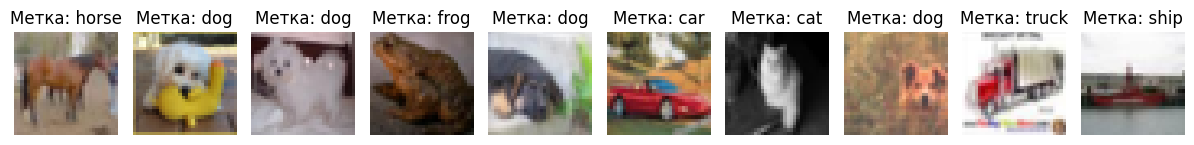

In [ ]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

images, labels = next(iter(train_loader))

print("Размерности данных:")
print("Количество тренировочных примеров = ", len(train_dataset) )
print("Количество тестовых примеров = ", len(test_dataset))
print("Форма одного изображения = ", images[0].shape)
print("Форма всех меток = ", labels.shape)

print("Демонстрация изображений и меток классов для подтверждения корректности загрузки:")
fig, axes = plt.subplots(1, 10, figsize=(12, 3))
for i in range(10):
    ax = axes[i]
    img = images[i].numpy().transpose(1, 2, 0)
    img = np.clip(img * std + mean, 0, 1)
    ax.imshow(img)
    ax.set_title(f'Метка: {classes[labels[i].item()]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout2d(0.25)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.dropout2 = nn.Dropout2d(0.25)

        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(128)
        self.conv6 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.dropout3 = nn.Dropout2d(0.25)

        self.fc1 = nn.Linear(128 * 4 * 4, 512)
        self.dropout4 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 256)
        self.dropout5 = nn.Dropout(0.5)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, X):
        X = F.relu(self.bn1(self.conv1(X)))
        X = F.relu(self.bn2(self.conv2(X)))
        X = self.pool1(X)
        X = self.dropout1(X)

        X = F.relu(self.bn3(self.conv3(X)))
        X = F.relu(self.bn4(self.conv4(X)))
        X = self.pool2(X)
        X = self.dropout2(X)

        X = F.relu(self.bn5(self.conv5(X)))
        X = F.relu(self.bn6(self.conv6(X)))
        X = self.pool3(X)
        X = self.dropout3(X)

        X = X.view(-1, 128 * 4 * 4)

        X = F.relu(self.fc1(X))
        X = self.dropout4(X)
        X = F.relu(self.fc2(X))
        X = self.dropout5(X)
        X = self.fc3(X)

        return X

In [ ]:
model = CNN().to(device)
print(model)

error_function = nn.CrossEntropyLoss()
update_parameters = optim.Adam(model.parameters(), lr=0.001)
learning_rate = optim.lr_scheduler.StepLR(update_parameters, step_size=10, gamma=0.5)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout2d(p=0.25, inplace=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout2d(p=0.25, inplace=False)
  (conv5): Conv2d(64, 

In [ ]:
import time
epochs = 30
train_classification_errors = []

for epoch in range(epochs):
    start_time = time.time()

    model.train()
    train_error = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        update_parameters.zero_grad()

        outputs = model(inputs)
        error = error_function(outputs, labels)

        error.backward()
        update_parameters.step()

        train_error += float(error)
        predicted = torch.argmax(outputs, dim=1)
        train_total += labels.shape[0]
        epoch_correct += torch.sum(predicted == labels).item()

    train_classification_error = train_error / len(train_loader)
    train_accuracy = epoch_correct / train_total

    train_classification_errors.append(train_classification_error)

    epoch_time = time.time() - start_time
    print(f"Эпоха {epoch + 1:2d}/{epochs} | "
          f"Ошибка классификации: {train_classification_error:.4f} | "
          f"Точность: {train_accuracy * 100:.2f}% | "
          f"Время: {epoch_time:.2f}с")

    learning_rate.step()

C:\Users\denis\AppData\Local\Temp\ipykernel_16268\242542697.py:24: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  train_error += float(error)


NameError: name 'total' is not defined

In [ ]:
model.eval()
start_time = time.time()
test_error = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        error = error_function(outputs, labels)

        test_error += float(error)
        predicted = torch.argmax(outputs, dim=1)
        test_total += labels.shape[0]
        test_correct += torch.sum(predicted == labels).item()

final_test_error = test_error / len(test_loader)
final_accuracy = test_correct / test_total

test_time = time.time() - start_time
print("Результаты:")
print(f"Ошибка классификации на тестовом наборе: {final_test_error:.4f}")
print(f"Точность на тестовом наборе: {final_accuracy * 100:.2f}%")
print(f"Время: {test_time:.2f}с")


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_classification_errors)
plt.xlabel('Эпоха')
plt.ylabel('Ошибка классификации')
plt.title('Изменение ошибки в процессе обучения')
plt.grid(True)
plt.show()